In [ ]:
import numpy as np
import plotly.express as px
import torch 

# Im in
torch.manual_seed(1337)


In [70]:
def plot(x):
    n = int(np.sqrt(data.shape[0]))
    x = x[:,2].reshape(n,n)
    fig = px.imshow(x, width=400, height=400,color_continuous_scale="Viridis",)
    fig.update_coloraxes(showscale=False)
    fig.update_xaxes(tickvals=[0, n-1])
    fig.update_yaxes(tickvals=[0, n-1])
    fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))
    fig.show()

#### Goal
- We want our model to learn the group operation of the Symmetric Group

___

#### What even is a group?
A group is a set $G$ with some binary operation $\ast$ that satisfies the following four axioms
1. **Closure** : combining two elements stays in the set. $\;\qquad\qquad a \ast b \in G$
2. **Associativity** : Changing grouping doesn't change result. $\qquad (a \ast b) \ast c = a \ast (b \ast c)$
3. **Identity**: There's an element that does nothing. $\;\quad\qquad\qquad \exists e \in G \text{ such that } a \ast e = e \ast a = a$
4. **Inverse**: Every element can be undone. $\;\;\qquad\qquad\qquad\qquad\forall a \in G, \exists a^{-1} \in G, \text{ such that } a \ast a^{-1} = a^{-1} \ast a = e$
We often denote our group as a pair $(G, \ast)$

#### Example of a group : Integers modulo n
Let $\mathbb{Z}_n = \{0,1,2,\dots, n-1\}$, with operation $a + b = (a+b) \mod n$. 

Then $(\mathbb{Z}_n, +)$ is a group.  
Proof, we see $\forall a,b,c \in \mathbb{Z}_n$, we have:
1. **Closure:** $\;\;\qquad a+b \in \mathbb{Z}_n$
2. **Associative:** $\,\quad a+(b+c) = (a+b) + c$
3. **Identity:** $\quad \;\;\;\;\; \exists e  = 0\in G$ such that $a + 0 = 0 + a = a$ 
4. **Inverses:** $\,\qquad \exists a^{-1} = -a \mod n \in G$ such that $a + (-a) = 0$

___
### What is a permutation?
- A permutation is just a rearrangement of $n$ objects. 
- More rigorously, a permutation of $n$ objects is a bijection $\sigma : \{1,\dots, n\} \to \{1, \dots, n\}$ that sends a list of $n$ elements to another list of $n$ elements

___
#### What is the symmetric group?
The symmetric group, denoted is a pair $(S_n, \circ)$ of all possible orderings of $n$ elements, with group operation as function composition:
$$(\sigma \tau)(x) = \sigma(\tau(x))$$
There are $n!$ ways to rearrange n objects, for the order (number of elements) of $S_n$ is $|S_n| = n!$
For example: 
- Consider $S_3$ which is interested in the permutations of the three objects $\{1,2,3\}$
- Then there are $|S_3| = 3! = 6$ ways to arrange them:
$$
\begin{aligned}
e     &= (1,2,3) \mapsto (1,2,3) \\
(1,2) &= (1,2,3) \mapsto (2,1,3) \\
(1,3) &= (1,2,3) \mapsto (3,2,1) \\
(2,3) &= (1,2,3) \mapsto (1,3,2) \\
(1,2,3) &= (1,2,3) \mapsto (2,3,1) \\
(1,3,2) &= (1,2,3) \mapsto (3,1,2)
\end{aligned}
$$


- An example group operation is $(1,2)(1,3)$ which sends 
$$
\begin{array}{c}
(1,2,3) \\
\quad\downarrow^{(1,3)} \\
(3,2,1) \\
\quad\downarrow^{(1,2)} \\
(3,1,2)
\end{array}
$$
Comparing we see $1 \mapsto 3$ and $2 \mapsto 1$ and $3 \mapsto 2$ so the permutation is:
$$(1,2)(1,3) = (1,2,3) \mapsto (3,1,2)$$
The symmetric group satisfies the group axioms [(proof)](https://en.wikipedia.org/wiki/Symmetric_group)
___

### Getting the symmetric group in python

In [71]:
# Docs: https://docs.sympy.org/latest/modules/combinatorics/named_groups.html
from sympy.combinatorics.named_groups import SymmetricGroup

# Create the S3 symmetric group
G = SymmetricGroup(3)
elements = list(G.generate_schreier_sims(af=True)) # generate all elements of G using Schreier–Sims algorithm as array form

# Print the elements (1 indexed)
print(f"The group S_3 has {G.order()} elements")
print(f"\nThe elements in S_3 are:")
for a in elements:
    print([x + 1 for x in a])

# Print the elements how sympy represents them (0 indexed)
print(f"\nThe elements in S_3 are (0 indexed):")
for a in elements:
    print(a)



The group S_3 has 6 elements

The elements in S_3 are:
[1, 2, 3]
[2, 3, 1]
[3, 1, 2]
[1, 3, 2]
[2, 1, 3]
[3, 2, 1]

The elements in S_3 are (0 indexed):
[0, 1, 2]
[1, 2, 0]
[2, 0, 1]
[0, 2, 1]
[1, 0, 2]
[2, 1, 0]


How will we build the dataset?

In [72]:
G = SymmetricGroup(3)
elements = list(G.generate_schreier_sims())

# Print elements
# Note : sympy denotes the identity as 2, so (2) = e
# (2) just sends 2 to itself, so does nothign
for idx, a in enumerate(elements):
    print(f"{idx :<5} {a}")

# Let a be the second elemnt
a = elements[1]

# Let b be the third element
b = elements[2]

# Sympy lets overwrite `*` so a * b corresponds to multiplying permtuations
c = a * b
print(f"\nab = {a}{b} = {c}")


0     (2)
1     (0 1 2)
2     (0 2 1)
3     (1 2)
4     (2)(0 1)
5     (0 2)

ab = (0 1 2)(0 2 1) = (2)


Storing examples

In [73]:
# We store a training example as:
# [a_idx, b_idx, ab_idx]

# Let a be the 2nd elements of G
# Let b be the 3rd element of G
# Then we store the training example as:

[1, 2, elements.index(elements[1] * elements[2])]

[1, 2, 0]

In [74]:

# Number of elements in the permuation
n = 5

G = SymmetricGroup(n)
elements = list(G.generate_schreier_sims())

# Number of elements in the group
m = len(elements)

# Instead of looping over n, we loop over m since:
# m : number of elements (same as n in the mod n)
# n : number of objects in the permuation
data = np.zeros((m  **2, 3))
for i in range(m):
    for j in range(m ):
        c = elements[i] * elements[j]
        data[(i *m) + j] = [i,j, elements.index(c)]


plot(data)

#### Now we can build the dataset and train

In [75]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} to train")

Using cpu to train


In [ ]:
from grokkingexperiments.data import split_data
from grokkingexperiments.model import GrokkingModel
from grokkingexperiments.train import train_model

model = GrokkingModel(128, 256, m)
x_train, y_train, x_test, y_test = split_data(data, 0.4)

# Put model and datasets on the correct device
model = model.to(device)
x_train = x_train.to(device)
y_train = y_train.to(device)
x_test = x_test.to(device)
y_test = y_test.to(device)


metrics = train_model(250_000, model, x_train, y_train, x_test, y_test)

Epoch  0      | Loss 4.814  | Test loss 4.822  | Train accuracy 0.008  | Test accuracy 0.008 
Epoch  100    | Loss 1.884  | Test loss 8.113  | Train accuracy 0.736  | Test accuracy 0.000 
Epoch  200    | Loss 0.157  | Test loss 12.707 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  300    | Loss 0.061  | Test loss 13.807 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  400    | Loss 0.041  | Test loss 14.047 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  500    | Loss 0.032  | Test loss 14.076 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  600    | Loss 0.027  | Test loss 14.042 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  700    | Loss 0.024  | Test loss 13.989 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  800    | Loss 0.021  | Test loss 13.930 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  900    | Loss 0.019  | Test loss 13.877 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  1000   | Loss 0.018  | Test loss 13.830 | Train accur

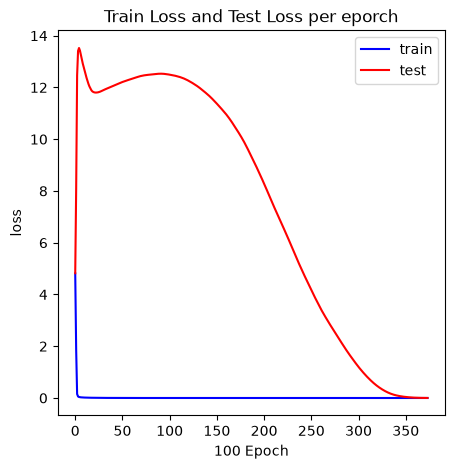

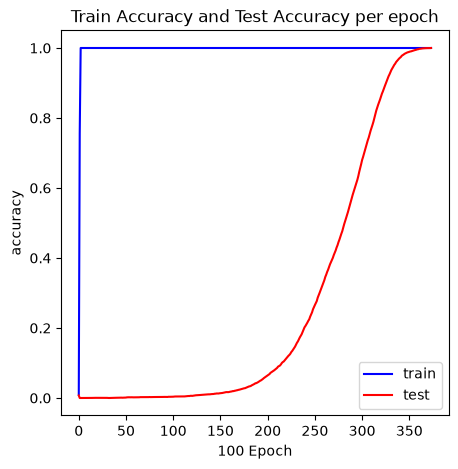

In [ ]:
from grokkingexperiments.utils import plot_metrics

# Unpack the metrics
training_losses = metrics[0]
test_losses = metrics[1]
training_accuracies = metrics[2]
test_accuracies = metrics[3]

# Plot the metrics 
plot_metrics(training_losses, test_losses, 'Train Loss and Test Loss per eporch', 'loss')
plot_metrics(training_accuracies, test_accuracies, 'Train Accuracy and Test Accuracy per epoch', 'accuracy')

